In [2]:
!pip -q install lightgbm

import os, json, joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from google.colab import files

os.makedirs("data/raw", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Upload: simulated_energy_data.csv, campus_rooms.csv, forecast_lgbm.joblib")
uploaded = files.upload()
for name in uploaded:
    dest = "models" if name.endswith(".joblib") else "data/raw"
    os.replace(name, f"{dest}/{name}")
print(os.listdir("data/raw"), os.listdir("models"))

Upload: simulated_energy_data.csv, campus_rooms.csv, forecast_lgbm.joblib


Saving forecast_lgbm.joblib to forecast_lgbm.joblib
['campus_rooms.csv', 'simulated_energy_data.csv'] ['forecast_lgbm.joblib']


In [4]:
DATA = "data/raw"
TARGET = "total_power_kw"

bundle = joblib.load("models/forecast_lgbm.joblib")
model, FEATURES, CATS = bundle["model"], bundle["features"], bundle["categories"]

df = pd.read_csv(f"{DATA}/simulated_energy_data.csv", parse_dates=["timestamp"])
rooms = pd.read_csv(f"{DATA}/campus_rooms.csv")[["room_id", "capacity"]]
df = (df.merge(rooms, on="room_id")
        .sort_values(["room_id", "timestamp"])
        .reset_index(drop=True))

# Same features used in notebook 01
g = df.groupby("room_id")[TARGET]
df["lag_24"] = g.shift(24)
df["lag_168"] = g.shift(168)
df["lag_336"] = g.shift(336)
df["same_hour_mean_7d"] = sum(g.shift(24 * k) for k in range(1, 8)) / 7
df["mean_prev_24h"] = g.transform(lambda s: s.shift(24).rolling(24).mean())
df["scheduled"] = df["scheduled"].astype(int)
df["sched_lag_168"] = df.groupby("room_id")["scheduled"].shift(168)
df["hour"] = df.timestamp.dt.hour
df["dow"] = df.timestamp.dt.dayofweek
for c, cats in CATS.items():
    df[c] = pd.Categorical(df[c], categories=cats)
df = df.dropna(subset=["lag_336"]).reset_index(drop=True)

# Keep only the period the model was NOT trained on (honest evaluation)
oos = df[df.timestamp >= "2026-11-01"].copy()

oos["pred_kw"] = model.predict(oos[FEATURES])

print(oos.shape, oos.timestamp.min(), "->", oos.timestamp.max())
oos[["timestamp", "room_id", TARGET, "pred_kw"]].head()


(12096, 25) 2026-11-01 00:00:00 -> 2026-11-21 23:00:00


,timestamp,room_id,total_power_kw,pred_kw
3528,2026-11-01 00:00:00,R01,0.283,0.301361
3529,2026-11-01 01:00:00,R01,0.275,0.300546
3530,2026-11-01 02:00:00,R01,0.283,0.296640
3531,2026-11-01 03:00:00,R01,0.272,0.293148
3532,2026-11-01 04:00:00,R01,0.264,0.293615


========== OVERALL MODEL PERFORMANCE ==========
MAE       0.04465
RMSE      0.14571
WAPE_%    7.40300
R2        0.95911
dtype: float64


/tmp/ipykernel_1879/201227043.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for room, group in oos.groupby("room_id"):



========== ROOM PERFORMANCE ==========


,MAE,RMSE,WAPE_%,R2,room_id
20,0.02451,0.05085,4.353,0.99095,R21
9,0.02452,0.06779,4.367,0.98837,R10
14,0.02638,0.10353,4.479,0.96510,R15
21,0.02381,0.04987,4.630,0.98891,R22
17,0.02157,0.04074,4.641,0.98992,R18
19,0.03275,0.06756,5.620,0.98497,R20
0,0.02924,0.07976,6.053,0.97820,R01
18,0.03354,0.07582,6.184,0.98098,R19
12,0.05386,0.17022,6.745,0.95890,R13
5,0.06479,0.20089,6.796,0.95899,R06



========== CAMPUS PERFORMANCE ==========
MAE       0.50291
RMSE      0.87208
WAPE_%    3.47400
R2        0.99458
dtype: float64


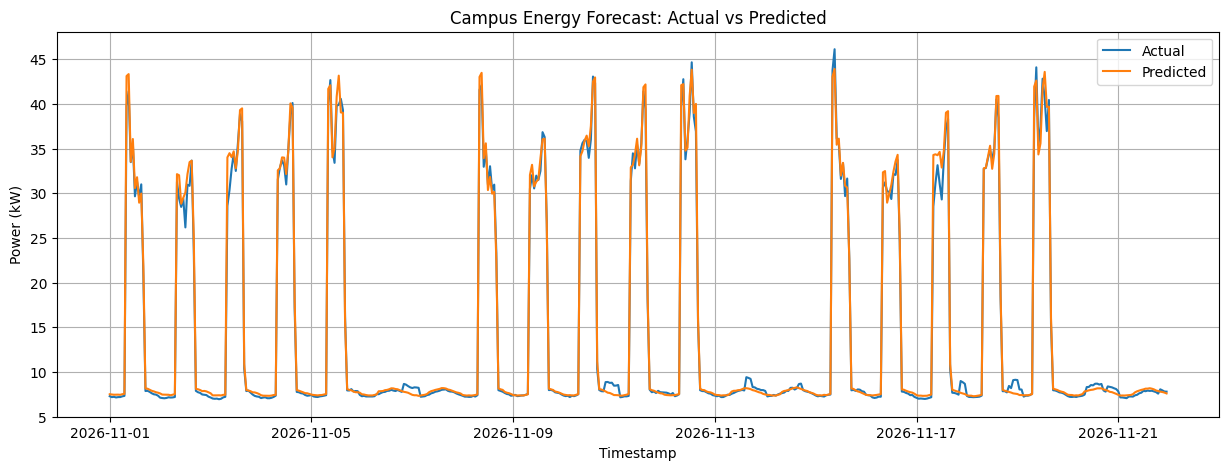

In [5]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = (
        np.sum(np.abs(y_true - y_pred)) /
        np.sum(np.abs(y_true))
    ) * 100
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": round(mae, 5),
        "RMSE": round(rmse, 5),
        "WAPE_%": round(wape, 3),
        "R2": round(r2, 5)
    }

# 1. Overall evaluation
overall = evaluate(oos[TARGET], oos["pred_kw"])

print("========== OVERALL MODEL PERFORMANCE ==========")
print(pd.Series(overall))

# 2. Room-level evaluation
room_results = []

for room, group in oos.groupby("room_id"):
    result = evaluate(group[TARGET], group["pred_kw"])
    result["room_id"] = room
    room_results.append(result)

room_metrics = pd.DataFrame(room_results)

print("\n========== ROOM PERFORMANCE ==========")
display(room_metrics.sort_values("WAPE_%"))

# 3. Campus-level evaluation
campus = oos.groupby("timestamp")[
    [TARGET, "pred_kw"]
].sum().reset_index()

campus_metrics = evaluate(
    campus[TARGET],
    campus["pred_kw"]
)

print("\n========== CAMPUS PERFORMANCE ==========")
print(pd.Series(campus_metrics))

# 4. Actual vs Predicted visualization
plt.figure(figsize=(15, 5))
plt.plot(campus["timestamp"], campus[TARGET], label="Actual")
plt.plot(campus["timestamp"], campus["pred_kw"], label="Predicted")
plt.title("Campus Energy Forecast: Actual vs Predicted")
plt.xlabel("Timestamp")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True)
plt.show()


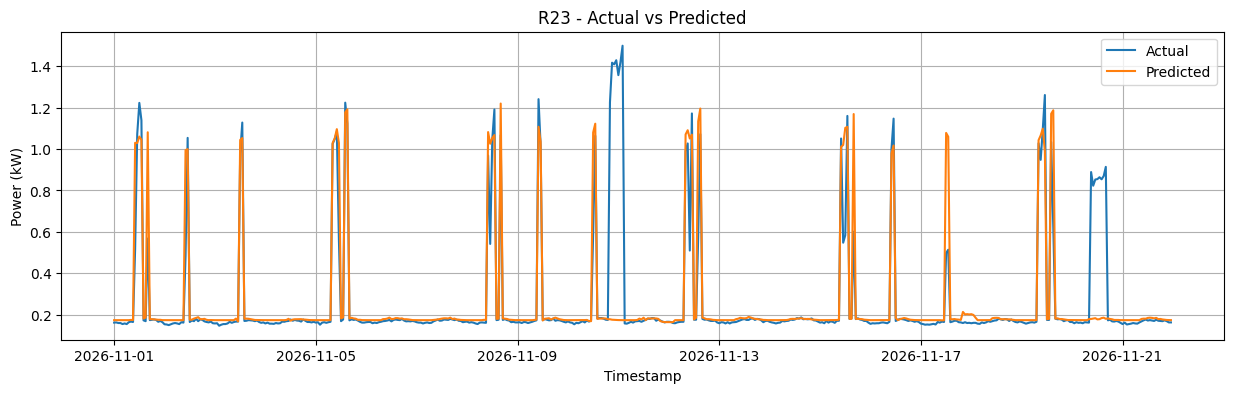

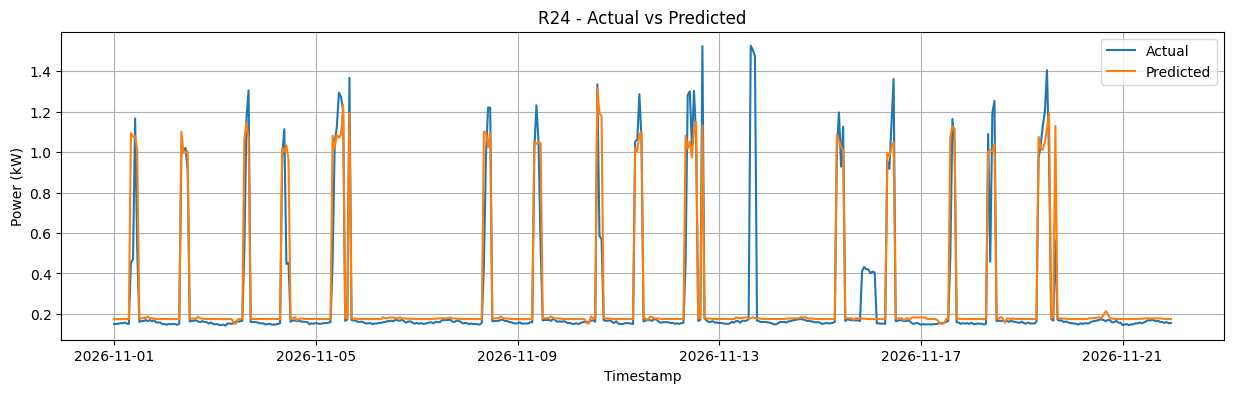

,MAE,RMSE,WAPE_%,R2,room_id,absolute_error
22,0.05555,0.19104,21.142,0.52102,R23,0.05555
23,0.05546,0.15473,19.871,0.76089,R24,0.05546
3,0.06196,0.18947,10.590,0.91168,R04,0.06196
1,0.04298,0.14631,9.075,0.93021,R02,0.04298
8,0.05063,0.15930,8.402,0.94141,R09,0.05063


In [6]:

# Investigate the two weakest rooms

weak_rooms = ["R23", "R24"]

for room in weak_rooms:
    room_data = (
        oos[oos["room_id"] == room]
        .sort_values("timestamp")
    )

    plt.figure(figsize=(15, 4))

    plt.plot(
        room_data["timestamp"],
        room_data[TARGET],
        label="Actual"
    )

    plt.plot(
        room_data["timestamp"],
        room_data["pred_kw"],
        label="Predicted"
    )

    plt.title(f"{room} - Actual vs Predicted")
    plt.xlabel("Timestamp")
    plt.ylabel("Power (kW)")
    plt.legend()
    plt.grid(True)
    plt.show()

# Compare error by room
room_metrics["absolute_error"] = room_metrics["MAE"]

display(
    room_metrics.sort_values(
        "WAPE_%",
        ascending=False
    ).head(5)
)


In [7]:

# Investigate largest prediction errors in R23 and R24

investigation = oos[
    oos["room_id"].isin(["R23", "R24"])
].copy()

investigation["error"] = (
    investigation[TARGET] - investigation["pred_kw"]
)

investigation["absolute_error"] = (
    investigation["error"].abs()
)

# Show the largest errors
columns_to_show = [
    "timestamp",
    "room_id",
    TARGET,
    "pred_kw",
    "error",
    "absolute_error",
    "scheduled",
    "lag_24",
    "lag_168",
    "lag_336",
    "same_hour_mean_7d",
    "mean_prev_24h",
    "hour",
    "dow"
]

columns_to_show = [
    c for c in columns_to_show
    if c in investigation.columns
]

worst_cases = (
    investigation
    .sort_values("absolute_error", ascending=False)
    [columns_to_show]
    .head(20)
)

display(worst_cases)


,timestamp,room_id,total_power_kw,pred_kw,error,absolute_error,scheduled,lag_24,lag_168,lag_336,same_hour_mean_7d,mean_prev_24h,hour,dow
96567,2026-11-13 15:00:00,R24,1.527,0.178282,1.348718,1.348718,0,0.170,0.167,0.166,0.227714,0.388417,15,4
92474,2026-11-11 02:00:00,R23,1.499,0.173877,1.325123,1.325123,0,0.161,0.157,0.165,0.160143,0.249417,2,2
96568,2026-11-13 16:00:00,R24,1.506,0.183255,1.322745,1.322745,0,1.525,0.166,0.170,0.418857,0.445083,16,4
96569,2026-11-13 17:00:00,R24,1.476,0.178840,1.297160,1.297160,0,0.177,0.170,0.164,0.171429,0.445250,17,4
92471,2026-11-10 23:00:00,R23,1.429,0.174372,1.254628,1.254628,0,0.163,0.163,0.170,0.164429,0.249208,23,1
92473,2026-11-11 01:00:00,R23,1.420,0.173877,1.246123,1.246123,0,0.163,0.162,0.166,0.163143,0.249375,1,2
92469,2026-11-10 21:00:00,R23,1.417,0.176042,1.240958,1.240958,0,0.170,0.165,0.173,0.166857,0.249208,21,1
92470,2026-11-10 22:00:00,R23,1.409,0.175315,1.233685,1.233685,0,0.166,0.161,0.173,0.164571,0.249208,22,1
92472,2026-11-11 00:00:00,R23,1.357,0.174307,1.182693,1.182693,0,0.168,0.158,0.167,0.163714,0.249417,0,2
92468,2026-11-10 20:00:00,R23,1.226,0.178314,1.047686,1.047686,0,0.173,0.172,0.175,0.170571,0.248958,20,1


========== MODEL FEATURES ==========
['hour', 'dow', 'scheduled', 'outside_temp_c', 'capacity', 'room_id', 'room_type', 'building_id', 'day_type', 'lag_24', 'lag_168', 'lag_336', 'same_hour_mean_7d', 'mean_prev_24h', 'sched_lag_168']


,feature,importance
3,outside_temp_c,1034
11,lag_336,756
10,lag_168,686
5,room_id,671
9,lag_24,636
12,same_hour_mean_7d,569
4,capacity,432
8,day_type,366
13,mean_prev_24h,349
0,hour,338


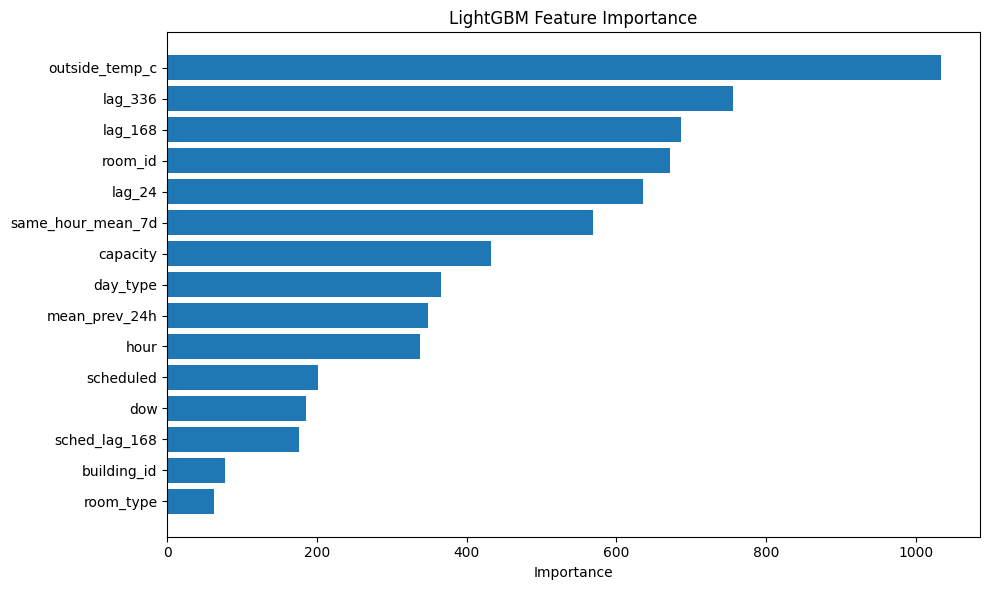

In [8]:

# 1. Inspect model features
print("========== MODEL FEATURES ==========")
print(FEATURES)

# 2. Feature importance
importance = pd.DataFrame({
    "feature": model.feature_name_,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

display(importance)

# 3. Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.gca().invert_yaxis()
plt.title("LightGBM Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [9]:

# Inspect original features around unusual events

events = [
    ("R23", "2026-11-10 20:00:00", "2026-11-11 03:00:00"),
    ("R24", "2026-11-13 13:00:00", "2026-11-13 19:00:00"),
    ("R23", "2026-11-20 08:00:00", "2026-11-20 17:00:00"),
]

for room, start, end in events:
    print(f"\n========== {room}: {start} ==========")

    sample = df[
        (df["room_id"] == room) &
        (df["timestamp"] >= start) &
        (df["timestamp"] <= end)
    ].copy()

    display(sample)



========== R23: 2026-11-10 20:00:00 ==========


,timestamp,building_id,room_id,occupancy,scheduled,waste_event,hvac_power_kw,lighting_power_kw,equipment_power_kw,total_power_kw,...,waste_type,capacity,lag_24,lag_168,lag_336,same_hour_mean_7d,mean_prev_24h,sched_lag_168,hour,dow
92468,2026-11-10 20:00:00,B03,R23,0,0,True,0.698,0.249,0.279,1.226,...,AFTER_HOURS_FULL,10,0.173,0.172,0.175,0.170571,0.248958,0.0,20,1
92469,2026-11-10 21:00:00,B03,R23,0,0,True,0.640,0.492,0.285,1.417,...,AFTER_HOURS_FULL,10,0.170,0.165,0.173,0.166857,0.249208,0.0,21,1
92470,2026-11-10 22:00:00,B03,R23,0,0,True,0.658,0.463,0.288,1.409,...,AFTER_HOURS_FULL,10,0.166,0.161,0.173,0.164571,0.249208,0.0,22,1
92471,2026-11-10 23:00:00,B03,R23,0,0,True,0.669,0.463,0.297,1.429,...,AFTER_HOURS_FULL,10,0.163,0.163,0.170,0.164429,0.249208,0.0,23,1
92472,2026-11-11 00:00:00,B03,R23,0,0,True,0.620,0.458,0.280,1.357,...,AFTER_HOURS_FULL,10,0.168,0.158,0.167,0.163714,0.249417,0.0,0,2
92473,2026-11-11 01:00:00,B03,R23,0,0,True,0.660,0.467,0.293,1.420,...,AFTER_HOURS_FULL,10,0.163,0.162,0.166,0.163143,0.249375,0.0,1,2
92474,2026-11-11 02:00:00,B03,R23,0,0,True,0.695,0.509,0.295,1.499,...,AFTER_HOURS_FULL,10,0.161,0.157,0.165,0.160143,0.249417,0.0,2,2
92475,2026-11-11 03:00:00,B03,R23,0,0,False,0.072,0.033,0.053,0.158,...,none,10,0.154,0.157,0.156,0.159571,0.248958,0.0,3,2



========== R24: 2026-11-13 13:00:00 ==========


,timestamp,building_id,room_id,occupancy,scheduled,waste_event,hvac_power_kw,lighting_power_kw,equipment_power_kw,total_power_kw,...,waste_type,capacity,lag_24,lag_168,lag_336,same_hour_mean_7d,mean_prev_24h,sched_lag_168,hour,dow
96565,2026-11-13 13:00:00,B03,R24,0,0,False,0.086,0.030,0.050,0.166,...,none,20,1.078,0.163,0.165,0.295857,0.388500,0.0,13,4
96566,2026-11-13 14:00:00,B03,R24,0,0,False,0.091,0.030,0.052,0.173,...,none,20,0.165,0.171,0.171,0.334714,0.388375,0.0,14,4
96567,2026-11-13 15:00:00,B03,R24,0,0,True,0.857,0.320,0.350,1.527,...,AFTER_HOURS_FULL,20,0.170,0.167,0.166,0.227714,0.388417,0.0,15,4
96568,2026-11-13 16:00:00,B03,R24,0,0,True,0.815,0.317,0.373,1.506,...,AFTER_HOURS_FULL,20,1.525,0.166,0.170,0.418857,0.445083,0.0,16,4
96569,2026-11-13 17:00:00,B03,R24,0,0,True,0.813,0.304,0.359,1.476,...,AFTER_HOURS_FULL,20,0.177,0.170,0.164,0.171429,0.445250,0.0,17,4
96570,2026-11-13 18:00:00,B03,R24,0,0,False,0.088,0.029,0.049,0.166,...,none,20,0.167,0.163,0.167,0.165286,0.445042,0.0,18,4
96571,2026-11-13 19:00:00,B03,R24,0,0,False,0.081,0.029,0.052,0.163,...,none,20,0.159,0.156,0.168,0.162429,0.444875,0.0,19,4



========== R23: 2026-11-20 08:00:00 ==========


,timestamp,building_id,room_id,occupancy,scheduled,waste_event,hvac_power_kw,lighting_power_kw,equipment_power_kw,total_power_kw,...,waste_type,capacity,lag_24,lag_168,lag_336,same_hour_mean_7d,mean_prev_24h,sched_lag_168,hour,dow
92696,2026-11-20 08:00:00,B03,R23,0,0,False,0.079,0.032,0.051,0.162,...,none,10,1.028,0.165,0.169,0.289571,0.204583,0.0,8,4
92697,2026-11-20 09:00:00,B03,R23,0,0,True,0.804,0.032,0.052,0.889,...,HVAC_LEFT_ON,10,0.948,0.169,0.170,0.279000,0.237167,0.0,9,4
92698,2026-11-20 10:00:00,B03,R23,0,0,True,0.742,0.031,0.049,0.823,...,HVAC_LEFT_ON,10,1.095,0.173,0.172,0.547714,0.275750,0.0,10,4
92699,2026-11-20 11:00:00,B03,R23,0,0,True,0.767,0.033,0.052,0.853,...,HVAC_LEFT_ON,10,1.261,0.177,0.175,0.520714,0.321125,0.0,11,4
92700,2026-11-20 12:00:00,B03,R23,0,0,True,0.772,0.031,0.052,0.855,...,HVAC_LEFT_ON,10,0.175,0.179,0.168,0.279429,0.321208,0.0,12,4
92701,2026-11-20 13:00:00,B03,R23,0,0,True,0.781,0.034,0.049,0.864,...,HVAC_LEFT_ON,10,0.175,0.175,0.175,0.366286,0.320958,0.0,13,4
92702,2026-11-20 14:00:00,B03,R23,0,0,True,0.770,0.032,0.052,0.854,...,HVAC_LEFT_ON,10,1.034,0.175,0.177,0.298857,0.356625,0.0,14,4
92703,2026-11-20 15:00:00,B03,R23,0,0,True,0.788,0.032,0.050,0.870,...,HVAC_LEFT_ON,10,0.623,0.181,0.175,0.242143,0.375292,0.0,15,4
92704,2026-11-20 16:00:00,B03,R23,0,0,True,0.828,0.033,0.052,0.914,...,HVAC_LEFT_ON,10,0.181,0.182,0.174,0.238429,0.375375,0.0,16,4
92705,2026-11-20 17:00:00,B03,R23,0,0,False,0.090,0.033,0.050,0.173,...,none,10,0.178,0.175,0.180,0.176429,0.375375,0.0,17,4


,feature,importance_mean,importance_std
2,scheduled,0.690777,0.011647
5,room_id,0.134297,0.001919
4,capacity,0.059506,0.001376
14,sched_lag_168,0.028788,0.000786
11,lag_336,0.027779,0.000235
6,room_type,0.021551,0.000566
3,outside_temp_c,0.014177,0.001436
10,lag_168,0.013345,0.000270
8,day_type,0.006435,0.000949
12,same_hour_mean_7d,0.006248,0.000189


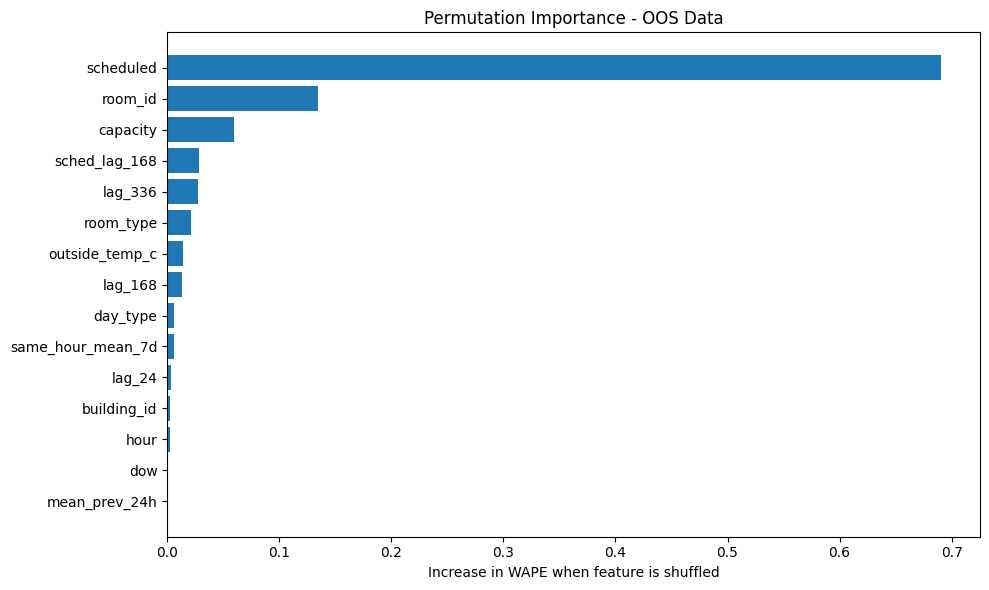

In [10]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use a representative sample of the OOS test data
sample = oos.sample(
    n=min(5000, len(oos)),
    random_state=42
)

X_sample = sample[FEATURES]
y_sample = sample[TARGET]

def wape_scorer(estimator, X, y):
    pred = estimator.predict(X)
    return -(
        np.sum(np.abs(y - pred)) /
        np.sum(np.abs(y))
    )

perm = permutation_importance(
    model,
    X_sample,
    y_sample,
    scoring=wape_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_results = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(perm_results)

plt.figure(figsize=(10, 6))
plt.barh(
    perm_results["feature"],
    perm_results["importance_mean"]
)
plt.gca().invert_yaxis()
plt.title("Permutation Importance - OOS Data")
plt.xlabel("Increase in WAPE when feature is shuffled")
plt.tight_layout()
plt.show()
